
# Lab 6: FEM 1D

### Exercise 1: Use FEM 1D to solve the EDO

Use FEM to solve the next EDO (improve the code seen in class). Compare with the analytical solution for some N elements.

\begin{equation}
-\dfrac{d^2y}{dx^2}=xe^x\,,\text{with}\; y(0)=(3-e)  \;, y(1)=0
\end{equation}


* Build a general scrip to solve a PDE of order two with Dirichlet's conditions: $y(a), y(b), x\,\epsilon\, [a,b]$. Use the method seen in class.

Nota: Solving the Green's function for this particular case we are able to find the analytical solution:
\begin{equation}
y(x) = 1-e-e^x(x-2)-x
\end{equation}

In [1]:
import numpy as np
import scipy.integrate as integrate
import matplotlib.pyplot as plt

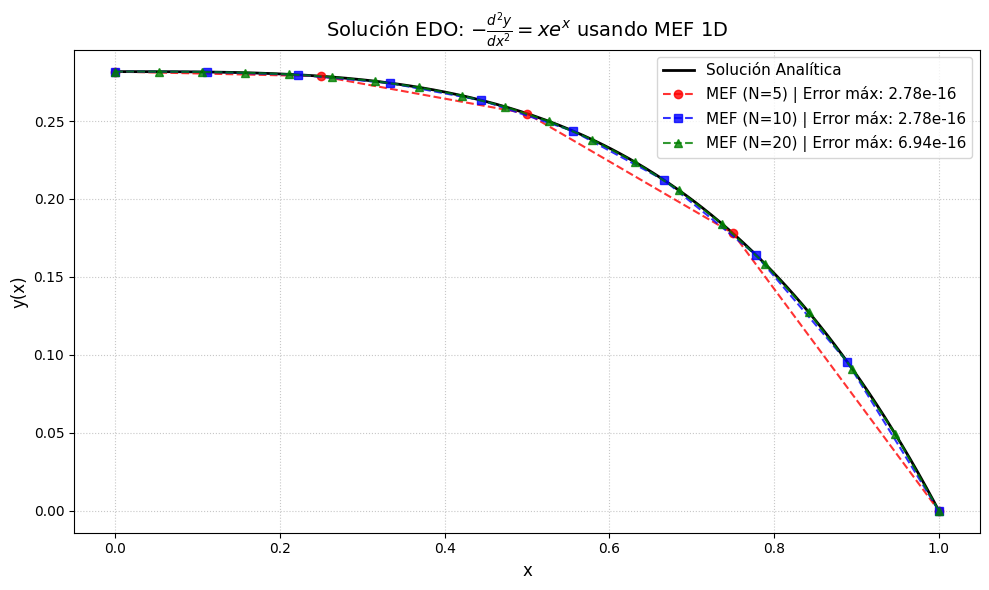

In [2]:
#1)definición de la funcion para usar FEM
def fem_1d(f, a, b, y_a, y_b, N):
    """
    Función general para resolver una EDO de segundo orden de la forma:
    -d^2y/dx^2 = f(x) en el dominio [a, b]
    con condiciones de frontera de Dirichlet: y(a) = y_a, y(b) = y_b.
    """
    #dominio
    xi = np.linspace(a, b, N)

    #Mmatriz de rígides K y vector de carga F
    K = np.zeros((N, N))
    F = np.zeros(N)


    for i in range(1, N):
        h_e = xi[i] - xi[i-1]


        K_e = np.array([[1.0, -1.0],
                        [-1.0, 1.0]]) / h_e

        #ensamblaje en la matriz global
        K[i-1:i+1, i-1:i+1] += K_e


        f_N1 = lambda x: f(x) * (xi[i] - x) / h_e
        f_N2 = lambda x: f(x) * (x - xi[i-1]) / h_e

        I_left, _  = integrate.quad(f_N1, xi[i-1], xi[i])
        I_right, _ = integrate.quad(f_N2, xi[i-1], xi[i])

        #actualizaciónn del vector de carga global
        F[i-1] += I_left
        F[i]   += I_right

    #condiciones de Dirichlet
    K_bc = K.copy()
    F_bc = F.copy()

    #valores en las fronteras
    for i in range(1, N-1):
        F_bc[i] -= K[i, 0] * y_a + K[i, N-1] * y_b

    #aislamiento de los nodos de frontera en la matriz de rigidez
    K_bc[0, :] = 0; K_bc[:, 0] = 0; K_bc[0, 0] = 1.0
    K_bc[-1, :] = 0; K_bc[:, -1] = 0; K_bc[-1, -1] = 1.0

    #valores del vector de carga
    F_bc[0] = y_a
    F_bc[-1] = y_b

    #solución del sistema de ecuaciones lineales
    y_sol = np.linalg.solve(K_bc, F_bc)

    return xi, y_sol


# 2) Configuración y resolución del problema


#definición del dominio y condiciones de frontera
a, b = 0.0, 1.0
y_a = 3.0 - np.e
y_b = 0.0

#función inicial: f(x) = x * e^x
f_func = lambda x: x * np.exp(x)

#solución analítica dada: y(x) = 1 - e - e^x(x - 2) - x
y_exacta = lambda x: 1.0 - np.e - np.exp(x) * (x - 2.0) - x

#lista de nodos
N_lista = [5, 10, 20]

#gráfica
plt.figure(figsize=(10, 6))

#solución analítica
x_fine = np.linspace(a, b, 200)
plt.plot(x_fine, y_exacta(x_fine), 'k-', linewidth=2, label='Solución Analítica')

estilos = [('red', 'o'), ('blue', 's'), ('green', '^')]

# Iterar sobre las diferentes cantidades de elementos y graficar
for N, (color, marcador) in zip(N_lista, estilos):
    x_mef, y_mef = fem_1d(f_func, a, b, y_a, y_b, N)

    #cálculo del error máximo absoluto respecto a la solución analítica
    error_max = np.max(np.abs(y_mef - y_exacta(x_mef)))

    plt.plot(x_mef, y_mef, color=color, marker=marcador, linestyle='--', alpha=0.8,
             label=f'MEF (N={N}) | Error máx: {error_max:.2e}')

plt.xlabel('x', fontsize=12)
plt.ylabel('y(x)', fontsize=12)
plt.title(r'Solución EDO: $-\frac{d^2y}{dx^2} = x e^x$ usando MEF 1D', fontsize=14)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()